<div style="text-align:center;">
  <img src="../../assets/SIMEM_logo_1.png" alt="Logo SIMEM" width="1300">
</div>

<div style="text-align:center;">
  <a href="https://www.simem.co/" style="color:#002989; font-weight:bold; font-size:2em; text-decoration:none;">Ir a SiMEM</a>
</div>

# Caso de Uso 3: Pronóstico de la Demanda de Energía Eléctrica a Corto Plazo (24-72 horas)
# Objetivos de este notebook

* Explicar cómo cargar datos históricos de demanda horaria desde un CSV o una API REST.
* Mostrar un análisis exploratorio básico de tendencia y estacionalidad diaria y semanal.
* Construir variables simples y explicables para un modelo de pronóstico de corto plazo.
* Entrenar y evaluar un modelo base de regresión lineal para pronosticar demanda futura.
* Interpretar cómo este tipo de modelo apoya la planeación operativa y la gestión del riesgo en el MEM colombiano.

**Índice**

1. [Instalación de librerías](#section1)
2. [Importación de librerías](#section2)
3. [Carga de datos](#section3)
4. [Preparación y análisis exploratorio](#section4)
5. [Modelado, evaluación y pronóstico](#section5)
6. [Uso del modelo en planeación y riesgo](#section6)

<a id='section1'></a>
# 1. Instalación de librerías
Ejecuta esta celda solo si necesitas instalar dependencias en tu ambiente local.

In [1]:
# import sys
# !{sys.executable} -m pip install pydataxm pandas numpy matplotlib scikit-learn requests python-dateutil holidays


<a id='section2'></a>
# 2. Importación de librerías
En este bloque importamos únicamente librerías estándar para análisis, visualización y modelado base.

In [2]:
from pathlib import Path
import warnings
import time
import datetime as dt

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import requests
import seaborn as sns

from dateutil.relativedelta import relativedelta
from pydataxm.pydatasimem import ReadSIMEM
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

try:
    import holidays as hol_lib
    _HOLIDAYS_OK = True
except ImportError:
    _HOLIDAYS_OK = False
    print("Advertencia: librería 'holidays' no encontrada. Ejecuta: pip install holidays")

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='talk')
plt.style.use('seaborn-v0_8-whitegrid')


In [3]:
# Directorios de trabajo del notebook
BASE_DIR = Path.cwd()
INPUT_DIR = BASE_DIR / 'input'
OUTPUT_DIR = BASE_DIR / 'output'
INPUT_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)

print(f'Directorio base: {BASE_DIR}')

Directorio base: c:\Users\50601\docs\API_XM\examples\casos_uso_analitica


Funciones auxiliares

Estas funciones permiten cargar datos desde CSV o API

In [4]:
def get_periods(start_date, end_date, months_per_period):
    """Divide el rango de consulta en periodos más pequeños para extracción por lotes."""
    if isinstance(start_date, str):
        start_date = dt.datetime.strptime(start_date, "%Y-%m-%d").date()

    if isinstance(end_date, str):
        end_date = dt.datetime.strptime(end_date, "%Y-%m-%d").date()

    periods = []
    current_date = start_date

    while current_date <= end_date:
        period_end = current_date + relativedelta(months=months_per_period) - dt.timedelta(days=1)
        if period_end > end_date:
            period_end = end_date

        periods.append((current_date, period_end))
        current_date = period_end + dt.timedelta(days=1)

    return periods


def consultar_dataset(dataset_id, fecha_inicial, fecha_final, meses_por_periodo=12, consultar=True):
    """Consulta la demanda comercial del SIMEM por bloques de tiempo."""
    if consultar:
        print(f"Consultando SIMEM para el rango: {fecha_inicial} - {fecha_final}")
        periodos = get_periods(fecha_inicial, fecha_final, meses_por_periodo)
        df = pd.DataFrame()

        for inicio_periodo, fin_periodo in periodos:
            print(f"  Lote: {inicio_periodo} -> {fin_periodo}")
            simem = ReadSIMEM(dataset_id=dataset_id, start_date=str(inicio_periodo), end_date=str(fin_periodo))
            df_lote = simem.main()
            df = pd.concat([df, df_lote], ignore_index=True)
            time.sleep(0.1)

        return df
    else:
        print("Omitiendo consulta al SIMEM. Se cargará el dataset desde un archivo CSV local.")


def guardar_csv(df, filename):
    """Guarda el DataFrame en un archivo CSV."""
    output_path = INPUT_DIR / filename
    df.to_csv(output_path, index=False, sep=",", encoding="utf-8-sig")
    print(f"Archivo guardado: {output_path}")

<a id='section3'></a>
# 3. Carga de datos
En este caso usaremos directamente el conjunto [Demanda Comercial](https://www.simem.co/datadetail/D552025A-D6E6-472A-B2CE-55D28C5FBED6) del SIMEM.
La extracción se hace por lotes, siguiendo la lógica de la celda 12 del caso 1, para evitar consultas demasiado grandes en una sola llamada.

In [5]:
# Dataset SIMEM: Demanda Comercial
dataset_id = "d55202"
fecha_inicial = "2026-01-01"
fecha_final = "2026-03-31"
meses_por_periodo = 3

# Parámetros alternativos por si luego quieres usar otra fuente
ruta_csv = INPUT_DIR / rf"demanda_comercial_{fecha_inicial}_{fecha_final}.csv"

CONSULTAR = True  # Cambia a True para consultar el SIMEM y guardar el CSV, o a False para cargar el CSV existente.

demanda_comercial = consultar_dataset(
    dataset_id=dataset_id,
    fecha_inicial=fecha_inicial,
    fecha_final=fecha_final,
    meses_por_periodo=meses_por_periodo,
    consultar=CONSULTAR, # Cambia a True para consultar el SIMEM y guardar el CSV, o a False para cargar el CSV existente.
)

Consultando SIMEM para el rango: 2026-01-01 - 2026-03-31
  Lote: 2026-01-01 -> 2026-03-31
****************************************************************************************************
Initializing object
The object has been initialized with the dataset: "Demanda comercial"
****************************************************************************************************
Inicio consulta sincronica
Creacion url: 0.0
Extraccion de registros: 18.657621383666992
End of data extracting process
****************************************************************************************************


In [6]:
if CONSULTAR:
    guardar_csv(demanda_comercial, f"demanda_comercial_{fecha_inicial}_{fecha_final}.csv")

Archivo guardado: c:\Users\50601\docs\API_XM\examples\casos_uso_analitica\input\demanda_comercial_2026-01-01_2026-03-31.csv


In [7]:
demanda_comercial = pd.read_csv(ruta_csv, parse_dates=["FechaHora"], encoding="utf-8-sig", sep=",")
demanda_comercial.head()

,CodigoVariable,FechaHora,CodigoSICAgente,TipoMercado,Version,Valor,UnidadMedida,CodigoDuracion
0,DdaCom,2026-01-28 23:00:00,ENDC,Regulado,TX3,961675.85,kWh,PT1H
1,DdaCom,2026-01-28 22:00:00,ENDC,Regulado,TX3,1177317.97,kWh,PT1H
2,DdaCom,2026-01-28 21:00:00,ENDC,Regulado,TX3,1385216.92,kWh,PT1H
3,DdaCom,2026-01-28 20:00:00,ENDC,Regulado,TX3,1556441.66,kWh,PT1H
4,DdaCom,2026-01-28 19:00:00,ENDC,Regulado,TX3,1643350.79,kWh,PT1H


In [8]:
demanda_comercial.info()

<class 'pandas.DataFrame'>
RangeIndex: 665544 entries, 0 to 665543
Data columns (total 8 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   CodigoVariable   665544 non-null  str           
 1   FechaHora        665544 non-null  datetime64[us]
 2   CodigoSICAgente  665544 non-null  str           
 3   TipoMercado      665544 non-null  str           
 4   Version          665544 non-null  str           
 5   Valor            665544 non-null  float64       
 6   UnidadMedida     665544 non-null  str           
 7   CodigoDuracion   665544 non-null  str           
dtypes: datetime64[us](1), float64(1), str(6)
memory usage: 40.6 MB


In [9]:
demanda_comercial["Fecha"] = demanda_comercial["FechaHora"].dt.date
df_trabajo = demanda_comercial.groupby(["FechaHora", "Version"])["Valor"].sum().divide(1e3).reset_index()
df_trabajo.head()

,FechaHora,Version,Valor
0,2026-01-01 00:00:00,TX2,8125.26955
1,2026-01-01 00:00:00,TX3,8125.26597
2,2026-01-01 00:00:00,TXF,8125.26597
3,2026-01-01 00:00:00,TXR,8125.26597
4,2026-01-01 01:00:00,TX2,8062.85091


In [10]:
def filtrar_ultima_version(df, columna_fecha, columna_version, columna_variable=None):  # Función para filtrar la última versión de registros por mes y variables (opcional)
    versiones = ["TX1", "TX2", "TXR", "TXF", "TX3", "TX4", "TX5", "TX6", "TX7", "TX8", "TX9", "TX10"]  # Lista de versiones ordenadas por prioridad
    version_orden = pd.Series(range(1, len(versiones) + 1), index=versiones)  # Serie que asigna un orden numérico a cada versión
    columna_año_mes = "año_mes"
    datos = df.copy()
    datos[columna_fecha] = pd.to_datetime(datos[columna_fecha])  # Conversión de la columna de fecha a tipo datetime
    datos[columna_año_mes] = datos[columna_fecha].dt.to_period("M")  # Se crea una columna con el año y mes del registro
    datos["orden_version"] = datos[columna_version].map(version_orden)  # Se asigna el orden de versión a cada fila

    if columna_variable is None:  # Si no se especifican variables adicionales
        df_filtrado = datos.sort_values([columna_año_mes, "orden_version"], ascending=[True, False])  # Ordena por mes y versión descendente
        df_filtrado = df_filtrado.drop_duplicates(subset=[columna_fecha], keep="first")  # Elimina duplicados conservando la última versión por fecha
    else:  # Si se especifican variables adicionales
        if isinstance(columna_variable, str):  # Convierte a lista si es un solo string
            columna_variable = [columna_variable]
        orden_columnas = columna_variable + [columna_año_mes, "orden_version"]  # Define el orden de columnas para ordenar
        df_filtrado = df_filtrado.sort_values(orden_columnas, ascending=[True] * len(columna_variable) + [True, False])  # Ordena por variables, mes y versión
        df_filtrado = df_filtrado.drop_duplicates(subset=columna_variable + [columna_fecha], keep="first")  # Elimina duplicados por variables y fecha

    df_filtrado = df_filtrado.drop(columns=[columna_año_mes, "orden_version"])  # Elimina columnas auxiliares
    return df_filtrado  # Retorna el DataFrame filtrado


df_filtrado = filtrar_ultima_version(df_trabajo, "FechaHora", "Version")

validacion_version_mes = (
    df_filtrado.assign(año_mes=df_filtrado["FechaHora"].dt.to_period("M"))
    .groupby("año_mes", as_index=False)["Version"]
    .nunique()
    .rename(
        columns={"Version": "versiones_unicas"},
    )
)

meses_con_multiples_versiones = validacion_version_mes[validacion_version_mes["versiones_unicas"] > 1]

if meses_con_multiples_versiones.empty:
    print("Validación OK: después del filtrado solo existe una versión por mes.")
else:
    print("Se encontraron meses con más de una versión después del filtrado:")
    display(meses_con_multiples_versiones)

validacion_version_mes

Validación OK: después del filtrado solo existe una versión por mes.


,año_mes,versiones_unicas
0,2026-01,1
1,2026-02,1
2,2026-03,1


In [11]:

# Prueba unitaria: validar cobertura horaria dentro del rango de fechas
def validar_rango_horario(df, col_fecha, fecha_inicio, fecha_fin):
    """
    Valida que todos los registros estén dentro del rango esperado y que
    no falten horas dentro de ese rango.
    """
    errores = []

    fechas = pd.to_datetime(df[col_fecha])

    # 1. Límites del rango
    inicio = pd.Timestamp(fecha_inicio)
    fin = pd.Timestamp(fecha_fin) + pd.Timedelta(hours=23)

    fuera_rango = df[(fechas < inicio) | (fechas > fin)]
    if not fuera_rango.empty:
        errores.append(f"  ✗ {len(fuera_rango)} registro(s) fuera del rango [{fecha_inicio}, {fecha_fin}].")

    # 2. Horas duplicadas
    duplicadas = fechas[fechas.duplicated()].unique()
    if len(duplicadas) > 0:
        errores.append(f"  ✗ {len(duplicadas)} hora(s) duplicada(s) detectada(s).")

    # 3. Horas faltantes en el rango continuo
    rango_completo = pd.date_range(start=inicio, end=fin, freq="h")
    horas_presentes = fechas.drop_duplicates().sort_values()
    horas_faltantes = rango_completo.difference(horas_presentes)
    if len(horas_faltantes) > 0:
        errores.append(f"  ✗ {len(horas_faltantes)} hora(s) faltante(s) en el rango continuo.")

    if errores:
        print("PRUEBA FALLIDA:")
        for e in errores:
            print(e)
        raise AssertionError("La validación del rango horario encontró problemas.")
    else:
        print(f"✓ Validación OK: {len(fechas)} registros dentro del rango [{fecha_inicio}, {fecha_fin}] sin horas faltantes ni duplicadas.")


validar_rango_horario(df_filtrado, "FechaHora", dt.datetime.strptime(fecha_inicial, "%Y-%m-%d"), dt.datetime.strptime(fecha_final, "%Y-%m-%d"))


✓ Validación OK: 2160 registros dentro del rango [2026-01-01 00:00:00, 2026-03-31 00:00:00] sin horas faltantes ni duplicadas.


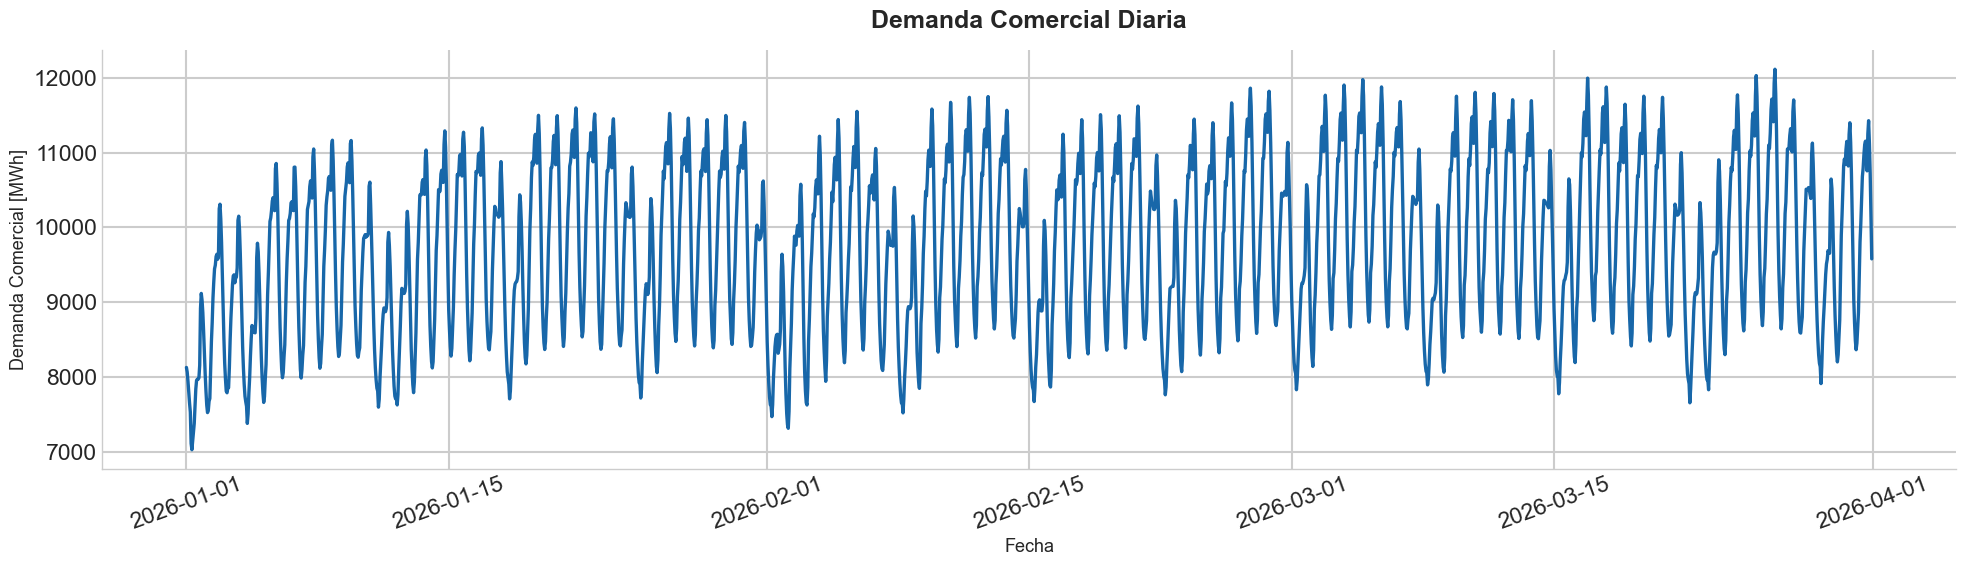

In [12]:
plt.figure(figsize=(20, 6))
ax = sns.lineplot(data=df_filtrado.sort_values("FechaHora"), x="FechaHora", y="Valor", color="#0B5FA5", linewidth=2.4, alpha=0.95)

# ax.fill_between(df_filtrado.sort_values("FechaHora")["FechaHora"], df_filtrado.sort_values("FechaHora")["Valor"], color="#8FB8DE", alpha=0.22)

ax.set_title("Demanda Comercial Diaria", fontsize=18, fontweight="bold", pad=16)
ax.set_xlabel("Fecha", fontsize=13)
ax.set_ylabel("Demanda Comercial [MWh]", fontsize=13)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

<a id='section4'></a>
# 4. Preparación y análisis exploratorio
Primero validamos continuidad horaria y luego analizamos tendencia, patrón diario y patrón semanal antes de construir variables para el modelo.

In [13]:
# Normalización básica de la serie horaria
demanda = (
    df_filtrado[["FechaHora", "Valor"]]
    .copy()
    .rename(columns={"FechaHora": "fecha_hora", "Valor": "demanda_MWh"})
    .drop_duplicates(subset=["fecha_hora"])
    .sort_values("fecha_hora")
 )
demanda = demanda.set_index("fecha_hora").asfreq("h")

faltantes = demanda["demanda_MWh"].isna().sum()
print(f"Registros horarios faltantes: {faltantes}")

if faltantes > 0:
    demanda["demanda_MWh"] = demanda["demanda_MWh"].interpolate(method="time")
    print("Se imputaron faltantes usando interpolación temporal.")

demanda.head()

Registros horarios faltantes: 0


,demanda_MWh
fecha_hora,
2026-01-01 00:00:00,8125.26597
2026-01-01 01:00:00,8062.84924
2026-01-01 02:00:00,7937.42157
2026-01-01 03:00:00,7782.34585
2026-01-01 04:00:00,7648.05149


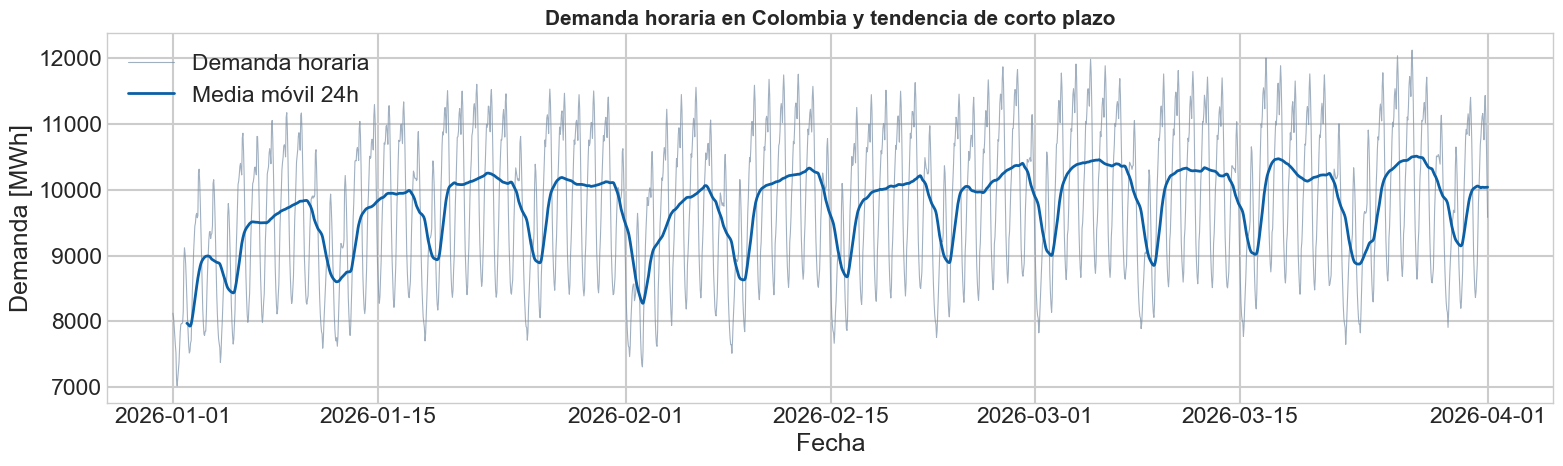

In [14]:
# Tendencia general y promedio móvil de 24 horas
serie = demanda['demanda_MWh']
media_movil_24h = serie.rolling(window=24).mean()

plt.figure(figsize=(16, 5))
plt.plot(serie.index, serie, color='#7A8FA6', linewidth=0.8, alpha=0.7, label='Demanda horaria')
plt.plot(media_movil_24h.index, media_movil_24h, color='#0B5FA5', linewidth=2, label='Media móvil 24h')
plt.title('Demanda horaria en Colombia y tendencia de corto plazo', fontsize=15, fontweight='bold')
plt.xlabel('Fecha')
plt.ylabel('Demanda [MWh]')
plt.legend()
plt.tight_layout()
plt.show()

### ¿Para qué sirve observar la tendencia de corto plazo?

La serie horaria contiene mucha variabilidad intradía. La **media móvil de 24 horas** ayuda a separar la señal estructural del ruido horario y aporta tres lecturas útiles:

1. **Nivel base de carga del sistema**: muestra si el sistema está operando sobre un nivel de demanda más alto o más bajo que el de días anteriores.
2. **Cambios recientes de régimen**: permite detectar transiciones operativas, por ejemplo, recuperación de demanda tras un festivo, disminuciones de fin de semana o cambios persistentes por temperatura, actividad económica o estacionalidad.
3. **Contexto para el pronóstico**: el modelo usa esta tendencia como una variable resumida del estado reciente del sistema. Esto evita depender solo de lags puntuales y mejora la estabilidad del pronóstico cuando una sola hora es atípica.

En términos operativos, esta tendencia es útil para:

- anticipar si la demanda de las próximas 24 a 72 horas viene en **ascenso, estabilidad o descenso**;
- contextualizar decisiones de programación de generación, compras y coberturas;
- identificar desvíos tempranos entre el comportamiento reciente y el patrón histórico esperado.


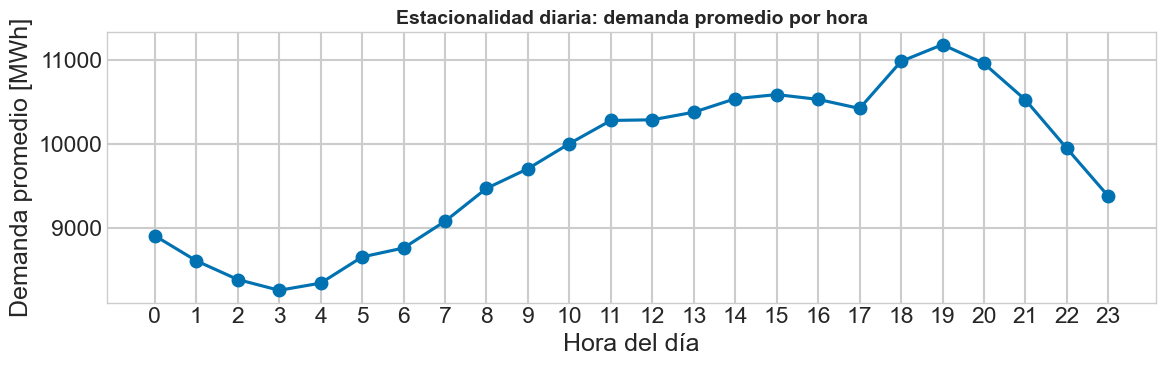

In [15]:
# Estacionalidad diaria: demanda promedio por hora
perfil_horario = demanda.assign(hora=demanda.index.hour).groupby('hora')['demanda_MWh'].mean()

plt.figure(figsize=(12, 4))
plt.plot(perfil_horario.index, perfil_horario.values, marker='o', color='#0072B2')
plt.title('Estacionalidad diaria: demanda promedio por hora', fontsize=14, fontweight='bold')
plt.xlabel('Hora del día')
plt.ylabel('Demanda promedio [MWh]')
plt.xticks(range(0, 24))
plt.tight_layout()
plt.show()

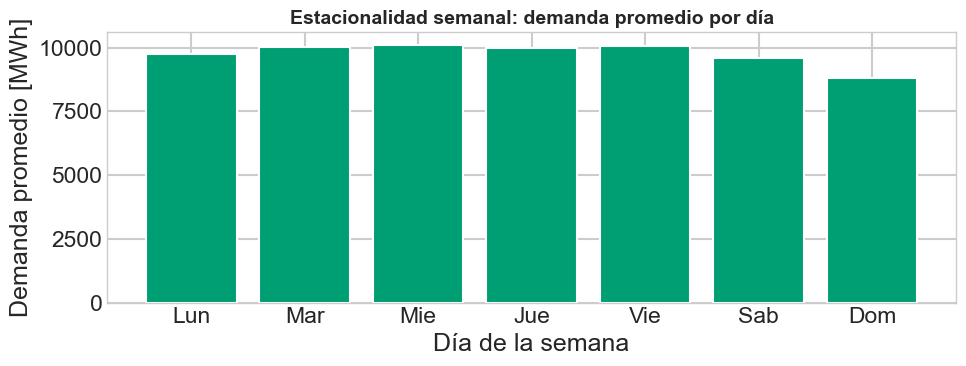

In [16]:
# Estacionalidad semanal: demanda promedio por día de la semana
nombres_dias = {0: 'Lun', 1: 'Mar', 2: 'Mie', 3: 'Jue', 4: 'Vie', 5: 'Sab', 6: 'Dom'}
perfil_semanal = demanda.assign(dia_semana=demanda.index.dayofweek).groupby('dia_semana')['demanda_MWh'].mean()
perfil_semanal.index = [nombres_dias[d] for d in perfil_semanal.index]

plt.figure(figsize=(10, 4))
plt.bar(perfil_semanal.index, perfil_semanal.values, color='#009E73')
plt.title('Estacionalidad semanal: demanda promedio por día', fontsize=14, fontweight='bold')
plt.xlabel('Día de la semana')
plt.ylabel('Demanda promedio [MWh]')
plt.tight_layout()
plt.show()

Preparación de variables

Para un modelo explicable de corto plazo, construiremos lags y variables temporales. Los lags capturan memoria reciente y las variables horarias capturan el calendario operativo.

### 4.1 Variables enriquecidas: tipo de día en Colombia y fenómeno El Niño

Se incorporan dos bloques de enriquecimiento antes del modelado:

1. **Tipo de día** — clasifica cada hora en: `LABORABLE`, `VISPERA` (día hábil anterior a festivo), `SABADO`, `DOMINGO` o `FESTIVO`. Cada categoría presenta un perfil de demanda diferenciado en el MEM colombiano.

2. **Indicador y corrección El Niño** — identifica horas que caen dentro de períodos históricos del fenómeno ENSO (índice ONI de NOAA) y aplica una imputación estadística para que los valores extremos no distorsionen el modelo base.

3. **Variables adicionales** — mes del año (`mes`), semana ISO (`semana_anio`) y promedio móvil de 168 h para capturar patrones semanales.


In [17]:
# ── Festivos y tipo de día en Colombia ──────────────────────────────────────
def construir_festivos_colombia(años):
    """Conjunto de fechas festivas oficiales en Colombia (Ley Emiliani incluida)."""
    if not _HOLIDAYS_OK:
        return set()
    festivos = set()
    for año in años:
        festivos.update(hol_lib.Colombia(years=año).keys())
    return festivos

FESTIVOS_CO = construir_festivos_colombia(range(2018, 2028))

def tipo_dia_colombia(ts, festivos=FESTIVOS_CO):
    """
    Clasifica un timestamp según el tipo de día operativo en el MEM colombiano.
    Prioridad: FESTIVO > VISPERA > SABADO > DOMINGO > LABORABLE
    """
    d   = pd.Timestamp(ts).date()
    dow = pd.Timestamp(ts).dayofweek          # 0=lun … 6=dom
    sig = d + dt.timedelta(days=1)
    if d in festivos:
        return "FESTIVO"
    if sig in festivos and dow < 5:           # víspera solo en días hábiles
        return "VISPERA"
    if dow == 5:
        return "SABADO"
    if dow == 6:
        return "DOMINGO"
    return "LABORABLE"

print(f"Festivos cargados: {len(FESTIVOS_CO)} fechas (2018-2027)")

# ── Períodos El Niño e imputación ────────────────────────────────────────────
# Fuente: NOAA Oceanic Niño Index (ONI ≥ 0.5 °C por ≥ 5 trimestres consecutivos)
PERIODOS_ELNINO = [
    ("2015-03-01", "2016-05-31"),   # El Niño fuerte 2015-2016
    ("2018-10-01", "2019-06-30"),   # El Niño débil  2018-2019
    ("2023-06-01", "2024-04-30"),   # El Niño fuerte 2023-2024
]

def marcar_elnino(index_horario):
    """Serie int (0/1): 1 si la hora cae dentro de un período El Niño."""
    flag = pd.Series(0, index=index_horario, dtype=int)
    for ini, fin in PERIODOS_ELNINO:
        flag[(index_horario >= ini) & (index_horario <= fin)] = 1
    return flag

def imputar_elnino(serie_demanda, es_nino, n_sigma=2.0):
    """
    Imputa outliers dentro de períodos El Niño usando la mediana de la misma
    combinación (hora, día_semana) calculada sobre registros en condición normal.

    Parámetros
    ----------
    serie_demanda : pd.Series  — serie horaria (DatetimeIndex)
    es_nino       : pd.Series  — bandera binaria 0/1
    n_sigma       : float      — umbral de detección (múltiplo de σ)

    Retorna
    -------
    serie_corregida, mascara_imputados
    """
    serie = serie_demanda.copy()

    datos_normales = pd.DataFrame({
        "demanda":     serie[es_nino == 0],
        "hora":        serie[es_nino == 0].index.hour,
        "dia_semana":  serie[es_nino == 0].index.dayofweek,
    })
    ref = datos_normales.groupby(["hora", "dia_semana"])["demanda"].agg(["median", "std"])

    imputados = pd.Series(False, index=serie.index)
    for idx in serie[es_nino == 1].index:
        h, dow = idx.hour, idx.dayofweek
        if (h, dow) in ref.index:
            med   = ref.loc[(h, dow), "median"]
            sigma = ref.loc[(h, dow), "std"]
            if sigma > 0 and abs(serie[idx] - med) > n_sigma * sigma:
                serie[idx]    = med
                imputados[idx] = True

    n_nino = int(es_nino.sum())
    n_imp  = int(imputados.sum())
    print(f"Registros en El Niño: {n_nino:,} | Outliers imputados: {n_imp:,} "
          f"({n_imp / max(n_nino, 1):.1%})")
    return serie, imputados


Festivos cargados: 178 fechas (2018-2027)


In [18]:
# Enriquecer la serie `demanda` con tipo_dia y es_nino, e imputar El Niño
es_nino = marcar_elnino(demanda.index)
demanda_corregida, mascara_imputados = imputar_elnino(demanda["demanda_MWh"], es_nino)

demanda["demanda_MWh_orig"] = demanda["demanda_MWh"].copy()   # copia del original
demanda["demanda_MWh"]      = demanda_corregida                # serie corregida
demanda["es_nino"]          = es_nino
demanda["tipo_dia"]         = pd.Series(
    [tipo_dia_colombia(ts) for ts in demanda.index],
    index=demanda.index
)

# Resumen del enriquecimiento
conteos = demanda["tipo_dia"].value_counts()
print("Distribución por tipo de día en el período consultado:")
print(conteos.to_string())
print(f"\nRegistros totales: {len(demanda):,} horas")


Registros en El Niño: 0 | Outliers imputados: 0 (0.0%)
Distribución por tipo de día en el período consultado:
tipo_dia
LABORABLE    1464
SABADO        312
DOMINGO       312
FESTIVO        72

Registros totales: 2,160 horas


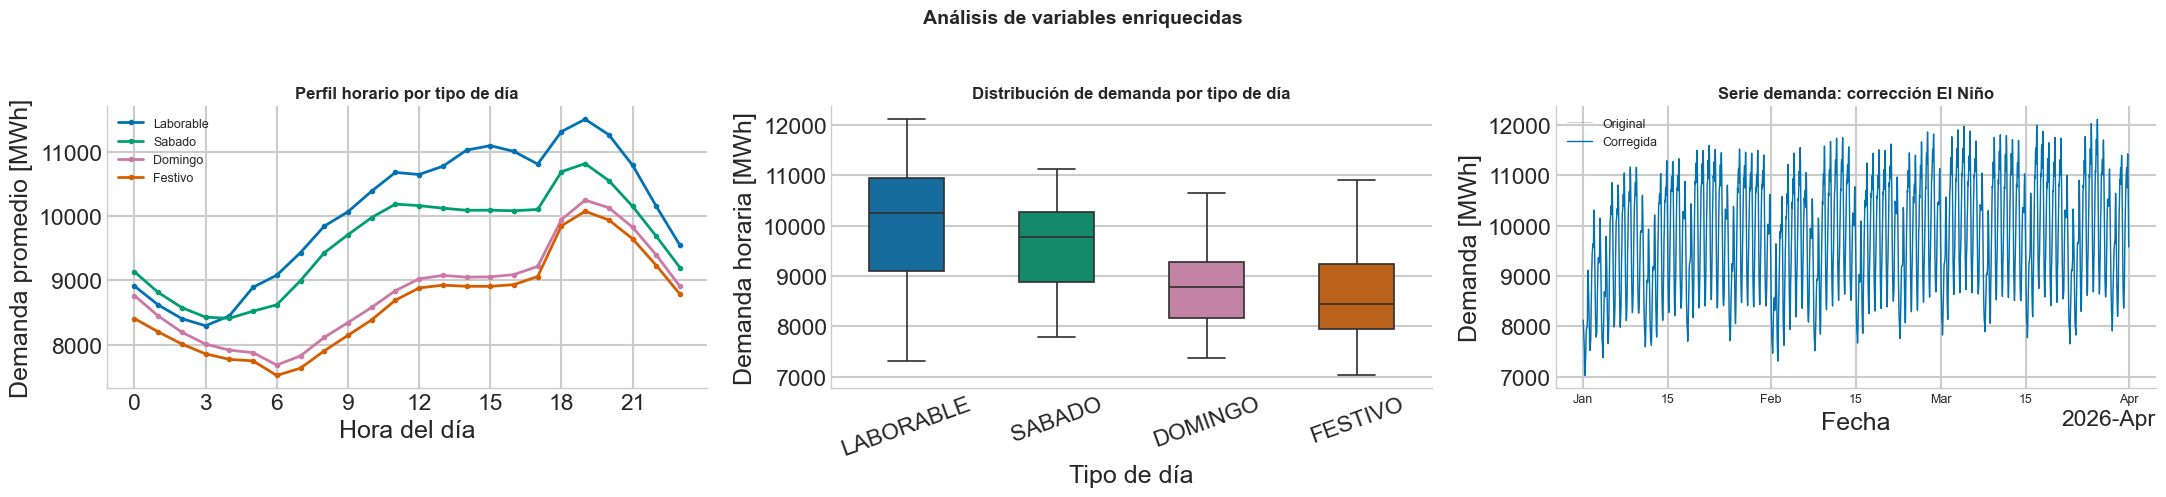

In [19]:
# Visualización: perfil horario y distribución por tipo de día + El Niño
TIPO_COLORES = {
    "LABORABLE": "#0072B2",
    "VISPERA":   "#F0A500",
    "SABADO":    "#009E73",
    "DOMINGO":   "#CC79A7",
    "FESTIVO":   "#D55E00",
}
TIPO_ORDEN = ["LABORABLE", "VISPERA", "SABADO", "DOMINGO", "FESTIVO"]

fig, axes = plt.subplots(1, 3, figsize=(22, 5))

# ── Panel 1: Perfil horario por tipo de día ──────────────────────────────────
for tdco in TIPO_ORDEN:
    sub = demanda[demanda["tipo_dia"] == tdco]
    if sub.empty:
        continue
    perfil = sub.groupby(sub.index.hour)["demanda_MWh"].mean()
    axes[0].plot(
        perfil.index, perfil.values,
        marker="o", markersize=3, linewidth=2,
        label=tdco.capitalize(), color=TIPO_COLORES[tdco]
    )
axes[0].set_title("Perfil horario por tipo de día", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Hora del día")
axes[0].set_ylabel("Demanda promedio [MWh]")
axes[0].set_xticks(range(0, 24, 3))
axes[0].legend(fontsize=9, frameon=False)
axes[0].spines[["top", "right"]].set_visible(False)

# ── Panel 2: Boxplot de demanda por tipo de día ──────────────────────────────
orden_presente = [t for t in TIPO_ORDEN if t in demanda["tipo_dia"].values]
sns.boxplot(
    data=demanda, x="tipo_dia", y="demanda_MWh",
    order=orden_presente,
    palette={t: TIPO_COLORES[t] for t in orden_presente},
    ax=axes[1], width=0.5, linewidth=1.2,
)
axes[1].set_title("Distribución de demanda por tipo de día", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Tipo de día")
axes[1].set_ylabel("Demanda horaria [MWh]")
axes[1].tick_params(axis="x", rotation=20)
axes[1].spines[["top", "right"]].set_visible(False)

# ── Panel 3: Serie con regiones El Niño e imputaciones ───────────────────────
axes[2].plot(
    demanda.index, demanda["demanda_MWh_orig"],
    color="#AAAAAA", linewidth=0.6, alpha=0.7, label="Original"
)
axes[2].plot(
    demanda.index, demanda["demanda_MWh"],
    color="#0072B2", linewidth=1.0, label="Corregida"
)

for ini, fin in PERIODOS_ELNINO:
    start_ts = pd.Timestamp(ini)
    end_ts   = pd.Timestamp(fin)
    if start_ts <= demanda.index[-1] and end_ts >= demanda.index[0]:
        axes[2].axvspan(
            max(start_ts, demanda.index[0]),
            min(end_ts, demanda.index[-1]),
            alpha=0.15, color="#D55E00", label="El Niño"
        )

if mascara_imputados.any():
    axes[2].scatter(
        demanda.index[mascara_imputados],
        demanda.loc[mascara_imputados, "demanda_MWh"],
        color="#D55E00", s=12, zorder=5, label="Imputados"
    )

axes[2].set_title("Serie demanda: corrección El Niño", fontsize=12, fontweight="bold")
axes[2].set_xlabel("Fecha")
axes[2].set_ylabel("Demanda [MWh]")

# Formateo legible del eje temporal para evitar etiquetas superpuestas
locator = mdates.AutoDateLocator(minticks=4, maxticks=6)
formatter = mdates.ConciseDateFormatter(locator)
axes[2].xaxis.set_major_locator(locator)
axes[2].xaxis.set_major_formatter(formatter)
axes[2].tick_params(axis="x", rotation=0, labelsize=9)

handles, labels_ = axes[2].get_legend_handles_labels()
seen = {}
for h, l in zip(handles, labels_):
    seen.setdefault(l, h)
axes[2].legend(seen.values(), seen.keys(), fontsize=9, frameon=False)
axes[2].spines[["top", "right"]].set_visible(False)

plt.suptitle("Análisis de variables enriquecidas", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()


In [20]:
def crear_variables_enriquecidas(df):
    """
    Crea el conjunto completo de variables para el modelo de pronóstico de demanda:

    Temporales básicas   : hora, dia_semana, mes, semana_anio
    Tipo de día Colombia : es_festivo, es_vispera, es_sabado, es_domingo
                          (LABORABLE es la categoría base — sin dummy)
    El Niño              : es_nino (1 si la hora cae en período ENSO activo)
    Rezagos              : lag_1, lag_2, lag_24, lag_48, lag_168
    Promedios móviles    : promedio_24h, promedio_semana
    """
    datos = df.copy()

    # ── Temporales básicas ────────────────────────────────────────────────────
    datos["hora"]        = datos.index.hour
    datos["dia_semana"]  = datos.index.dayofweek
    datos["mes"]         = datos.index.month
    datos["semana_anio"] = datos.index.isocalendar().week.astype(int)

    # ── Tipo de día Colombia (dummies) ────────────────────────────────────────
    if "tipo_dia" not in datos.columns:
        datos["tipo_dia"] = pd.Series(
            [tipo_dia_colombia(ts) for ts in datos.index], index=datos.index
        )
    datos["es_festivo"] = (datos["tipo_dia"] == "FESTIVO").astype(int)
    datos["es_vispera"] = (datos["tipo_dia"] == "VISPERA").astype(int)
    datos["es_sabado"]  = (datos["tipo_dia"] == "SABADO").astype(int)
    datos["es_domingo"] = (datos["tipo_dia"] == "DOMINGO").astype(int)

    # ── El Niño ───────────────────────────────────────────────────────────────
    if "es_nino" not in datos.columns:
        datos["es_nino"] = marcar_elnino(datos.index)

    # ── Rezagos ───────────────────────────────────────────────────────────────
    for lag in [1, 2, 24, 48, 168]:
        datos[f"lag_{lag}"] = datos["demanda_MWh"].shift(lag)

    # ── Promedios móviles ─────────────────────────────────────────────────────
    datos["promedio_24h"]    = datos["demanda_MWh"].shift(1).rolling(24).mean()
    datos["promedio_semana"] = datos["demanda_MWh"].shift(1).rolling(168).mean()

    return datos.drop(columns=["tipo_dia"], errors="ignore").dropna()


datos_modelo = crear_variables_enriquecidas(demanda)
print(f"Variables generadas: {list(datos_modelo.columns)}")
datos_modelo.head()


Variables generadas: ['demanda_MWh', 'demanda_MWh_orig', 'es_nino', 'hora', 'dia_semana', 'mes', 'semana_anio', 'es_festivo', 'es_vispera', 'es_sabado', 'es_domingo', 'lag_1', 'lag_2', 'lag_24', 'lag_48', 'lag_168', 'promedio_24h', 'promedio_semana']


,demanda_MWh,demanda_MWh_orig,es_nino,hora,dia_semana,mes,semana_anio,es_festivo,es_vispera,es_sabado,es_domingo,lag_1,lag_2,lag_24,lag_48,lag_168,promedio_24h,promedio_semana
fecha_hora,,,,,,,,,,,,,,,,,,
2026-01-08 00:00:00,8825.90340,8825.90340,0,0,3,1,2,0,0,0,0,9291.77115,9826.66487,8663.47794,8660.51287,8125.26597,9607.050675,8959.821389
2026-01-08 01:00:00,8502.09734,8502.09734,0,1,3,1,2,0,0,0,0,8825.90340,9291.77115,8354.50591,8351.92188,8062.84924,9613.818403,8963.991850
2026-01-08 02:00:00,8254.41043,8254.41043,0,2,3,1,2,0,0,0,0,8502.09734,8825.90340,8093.03202,8102.53705,7937.42157,9619.968046,8966.606422
2026-01-08 03:00:00,8114.43115,8114.43115,0,3,3,1,2,0,0,0,0,8254.41043,8502.09734,7983.19497,7987.02933,7782.34585,9626.692146,8968.493261
2026-01-08 04:00:00,8179.62646,8179.62646,0,4,3,1,2,0,0,0,0,8114.43115,8254.41043,8095.46824,8053.72727,7648.05149,9632.160320,8970.469959


In [21]:
# Variables predictoras enriquecidas y objetivo
variables_modelo = [
    # Temporales
    "hora", "dia_semana", "mes", "semana_anio",
    # Tipo de día Colombia
    "es_festivo", "es_vispera", "es_sabado", "es_domingo",
    # El Niño
    "es_nino",
    # Rezagos
    "lag_1", "lag_2", "lag_24", "lag_48", "lag_168",
    # Promedios móviles
    "promedio_24h", "promedio_semana",
]
objetivo = "demanda_MWh"

horizonte_prueba = 72  # horas para evaluación fuera de muestra

train = datos_modelo.iloc[:-horizonte_prueba].copy()
test  = datos_modelo.iloc[-horizonte_prueba:].copy()

X_train = train[variables_modelo]
y_train = train[objetivo]
X_test  = test[variables_modelo]
y_test  = test[objetivo]

print(f"Variables del modelo  : {len(variables_modelo)}")
print(f"Tamaño entrenamiento  : {X_train.shape}")
print(f"Tamaño prueba         : {X_test.shape}")


Variables del modelo  : 16
Tamaño entrenamiento  : (1920, 16)
Tamaño prueba         : (72, 16)


<a id='section5'></a>
# 5. Modelado, evaluación y pronóstico
Usaremos regresión lineal como línea base. Es simple, rápida, explicable y suficiente para mostrar la lógica del caso de uso antes de pasar a modelos más complejos.

In [22]:
# Entrenamiento del modelo base
modelo = LinearRegression()
modelo.fit(X_train, y_train)

pred_test = modelo.predict(X_test)
mae = mean_absolute_error(y_test, pred_test)
rmse = np.sqrt(mean_squared_error(y_test, pred_test))

print(f'MAE: {mae:,.2f} MWh')
print(f'RMSE: {rmse:,.2f} MWh')

MAE: 149.03 MWh
RMSE: 196.52 MWh


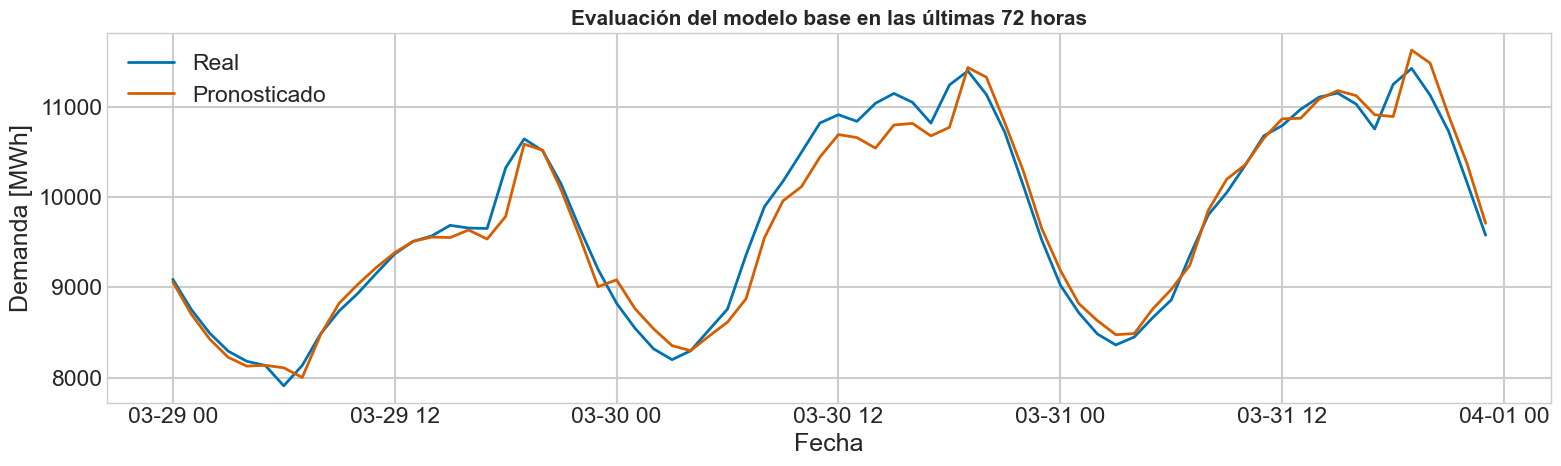

,real,pronosticado
fecha_hora,,
2026-03-31 19:00:00,11426.18696,11629.060868
2026-03-31 20:00:00,11129.78523,11485.193689
2026-03-31 21:00:00,10729.28811,10904.740719
2026-03-31 22:00:00,10158.32405,10369.851736
2026-03-31 23:00:00,9578.00000,9710.861752


In [23]:
# Comparación visual entre valores reales y pronosticados en la ventana de prueba
comparacion = pd.DataFrame({
    'real': y_test,
    'pronosticado': pred_test
}, index=y_test.index)

plt.figure(figsize=(16, 5))
plt.plot(comparacion.index, comparacion['real'], label='Real', linewidth=2, color='#0072B2')
plt.plot(comparacion.index, comparacion['pronosticado'], label='Pronosticado', linewidth=2, color='#D55E00')
plt.title('Evaluación del modelo base en las últimas 72 horas', fontsize=15, fontweight='bold')
plt.xlabel('Fecha')
plt.ylabel('Demanda [MWh]')
plt.legend()
plt.tight_layout()
plt.show()

comparacion.tail()

Pronóstico futuro

Para proyectar 24 a 72 horas hacia adelante con variables rezagadas, generamos predicciones de forma recursiva: cada nueva hora usa como insumo las predicciones anteriores.

In [24]:
def pronostico_recursivo(modelo, serie_historica, horas_futuras=72):
    """
    Genera pronóstico horario futuro usando el mismo conjunto de variables
    enriquecidas: tipo de día Colombia, El Niño, lags y promedios móviles.
    """
    historial = serie_historica.copy()

    # Pre-calcular flag El Niño para todas las horas futuras
    fechas_futuras = pd.date_range(
        historial.index[-1] + pd.Timedelta(hours=1),
        periods=horas_futuras, freq="h"
    )
    nino_futuro = marcar_elnino(fechas_futuras)

    predicciones = []
    fechas_pred  = []

    for i in range(horas_futuras):
        tf    = historial.index[-1] + pd.Timedelta(hours=1)
        tdco  = tipo_dia_colombia(tf)

        fila = {
            "hora":            tf.hour,
            "dia_semana":      tf.dayofweek,
            "mes":             tf.month,
            "semana_anio":     tf.isocalendar()[1],
            # Tipo de día Colombia
            "es_festivo":      int(tdco == "FESTIVO"),
            "es_vispera":      int(tdco == "VISPERA"),
            "es_sabado":       int(tdco == "SABADO"),
            "es_domingo":      int(tdco == "DOMINGO"),
            # El Niño
            "es_nino":         int(nino_futuro.iloc[i]),
            # Rezagos
            "lag_1":           historial.iloc[-1],
            "lag_2":           historial.iloc[-2],
            "lag_24":          historial.iloc[-24],
            "lag_48":          historial.iloc[-48],
            "lag_168":         historial.iloc[-168],
            # Promedios móviles
            "promedio_24h":    historial.iloc[-24:].mean(),
            "promedio_semana": historial.iloc[-168:].mean(),
        }

        X_futuro   = pd.DataFrame([fila])[variables_modelo]
        prediccion = modelo.predict(X_futuro)[0]

        historial.loc[tf] = prediccion
        fechas_pred.append(tf)
        predicciones.append(prediccion)

    return pd.DataFrame({"FechaHora": fechas_pred, "Pronostico_MWh": predicciones})


horizonte_futuro  = 24
pronostico_futuro = pronostico_recursivo(
    modelo          = modelo,
    serie_historica = demanda["demanda_MWh"],
    horas_futuras   = horizonte_futuro,
)
pronostico_futuro.head()

,FechaHora,Pronostico_MWh
0,2026-04-01 00:00:00,9209.951651
1,2026-04-01 01:00:00,8967.870878
2,2026-04-01 02:00:00,8788.952505
3,2026-04-01 03:00:00,8663.437049
4,2026-04-01 04:00:00,8660.963229


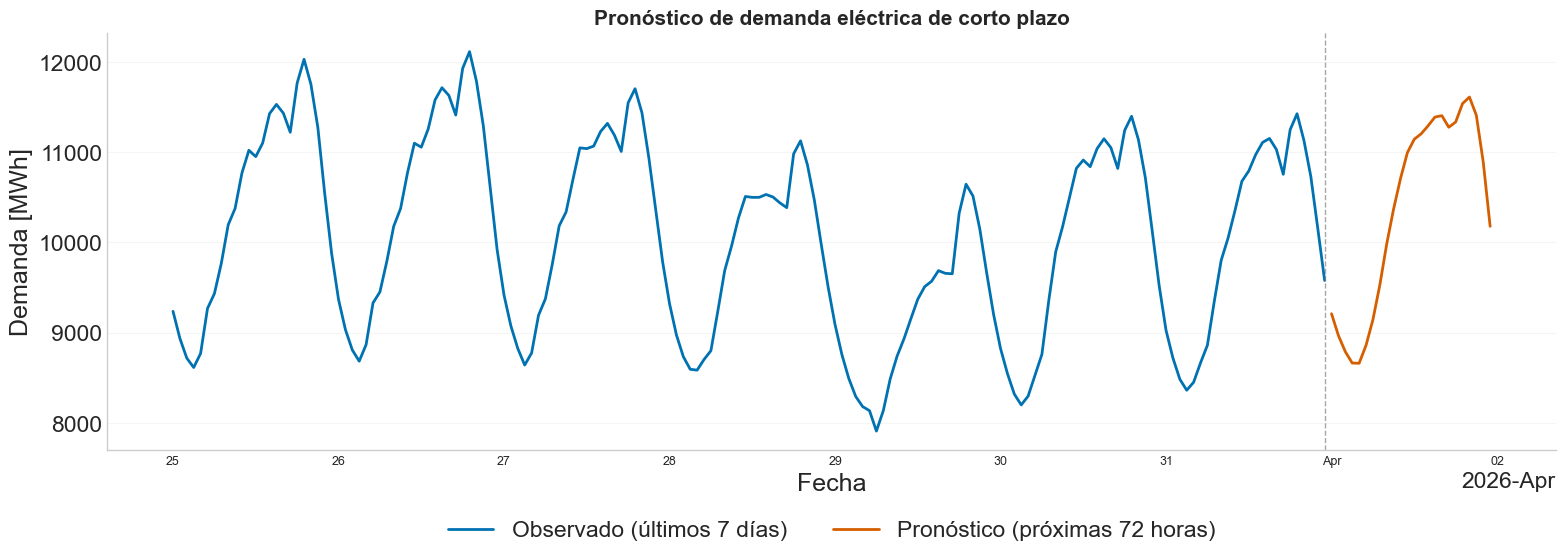

In [25]:
# Gráfico de los últimos 7 días observados y las próximas 72 horas pronosticadas
horas_observadas = 24 * 7
observado_reciente = demanda["demanda_MWh"].iloc[-horas_observadas:]

fig, ax = plt.subplots(figsize=(16, 6))

ax.plot(
    observado_reciente.index,
    observado_reciente.values,
    label="Observado (últimos 7 días)",
    linewidth=2,
    color="#0072B2",
)
ax.plot(
    pronostico_futuro["FechaHora"],
    pronostico_futuro["Pronostico_MWh"],
    label="Pronóstico (próximas 72 horas)",
    linewidth=2,
    color="#D55E00",
)
ax.axvline(observado_reciente.index[-1], color="gray", linestyle="--", linewidth=1, alpha=0.7)

ax.set_title("Pronóstico de demanda eléctrica de corto plazo", fontsize=15, fontweight="bold")
ax.set_xlabel("Fecha")
ax.set_ylabel("Demanda [MWh]")
ax.grid(True, axis="y", alpha=0.18, linewidth=0.8)
ax.grid(False, axis="x")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Formateo limpio del eje temporal
locator   = mdates.AutoDateLocator(minticks=5, maxticks=10)
formatter = mdates.ConciseDateFormatter(locator)
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(formatter)
ax.tick_params(axis="x", rotation=0, labelsize=9)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=2,
    frameon=False,
)

fig.tight_layout()
plt.show()


In [26]:
# Guardar resultado del pronóstico para uso operativo o integración con otros procesos
archivo_salida = OUTPUT_DIR / "pronostico_demanda_72h.csv"
pronostico_futuro.to_csv(archivo_salida, index=False)
print(f"Pronóstico guardado en: {archivo_salida}")
pronostico_futuro.tail()

Pronóstico guardado en: c:\Users\50601\docs\API_XM\examples\casos_uso_analitica\output\pronostico_demanda_72h.csv


,FechaHora,Pronostico_MWh
19,2026-04-01 19:00:00,11539.440704
20,2026-04-01 20:00:00,11611.603532
21,2026-04-01 21:00:00,11408.455820
22,2026-04-01 22:00:00,10889.774237
23,2026-04-01 23:00:00,10178.733390


Interpretación del modelo base

La regresión lineal aprende una relación directa entre la demanda futura y variables muy intuitivas:

* Comportamiento reciente de la demanda (lags 1, 2, 24, 48 y 168 horas).
* Efectos del calendario operativo (hora, día de la semana y fin de semana).
* Nivel reciente de carga mediante el promedio móvil de 24 horas.

Esto permite explicar el resultado ante áreas operativas, comerciales o de riesgo sin depender de modelos difíciles de auditar.

<a id='section6'></a>
# 6. Uso del modelo en planeación y riesgo

Este modelo apoya decisiones típicas del MEM colombiano de la siguiente forma:

* **Planeación operativa:** anticipa el nivel de demanda para programación de generación, compras y disponibilidad de recursos.
* **Gestión del riesgo:** permite identificar horas con posible presión sobre precios o necesidad de cobertura adicional.
* **Seguimiento comercial:** ayuda a contrastar demanda esperada versus observada para contratos, desvíos y exposición al mercado spot.
* **Escalabilidad analítica:** sirve como línea base para luego incorporar clima, festivos, indisponibilidades o variables macro del sistema.

Como siguiente paso, se puede comparar esta línea base contra Random Forest o XGBoost, pero conviene validar primero que la calidad del dato y la lógica temporal estén correctamente resueltas.